# 05 — Modelling, and whether the differences are measurable — Fisher's Iris

**Stages 4, 5b and 6 of the Tier A pipeline** (`DOCS/STRUCTURE.md`), Path B.

Notebook 04 left a prediction on the table: the problem is **one-dimensional** (LD1 carries 99.1%
of the separation), its two petal features are **0.94-correlated near-duplicates**, and the best
single measurement already scores **96.1%**. There is very little room left for a four-feature
model to prove itself.

This notebook measures the room. It does the ordinary thing — engineer features, run a model
bake-off, evaluate on held-out data — and then does the thing the ordinary workflow skips:
**it puts an error bar on the comparison.**

| § | Question | Why it matters |
|---|---|---|
| 5.2 | Which feature block earns its place? | The MECE test of Branch B vs Branch C |
| 5.3 | Which model family wins? | Reported **paired**, with a CI on the *difference* |
| 5.4 | How much does the random seed move the answer? | The hero exhibit |
| 5.5 | What difference is detectable at this sample size? | The reusable artefact |
| 5.6 | Which specimens are actually wrong? | Converts "accuracy" into named flowers |
| 5.7 | Do the notes' engineered features help? | A measured null result |
| 5.8 | Do the Stage 2 defects change anything? | Closes Key Line 1 |

Everything is scored on **one fixed set of 100 folds**, shared by every model, so differences can
be compared as paired quantities rather than as two independently wobbling means.

In [1]:
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

SRC_NAME = "Iris.csv"
ROOT = Path.cwd() if (Path.cwd() / SRC_NAME).exists() else Path.cwd().parent
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
REPORTS, FIGS = ROOT / "reports", ROOT / "reports" / "figures"
for d in (RAW, PROC, REPORTS, FIGS):
    d.mkdir(parents=True, exist_ok=True)

# ---- DESIGN.md palette (DOCS/DESIGN.md section 2) - defined inline, never re-picked -------
NAVY, BLUE, TEAL = "#051C2C", "#2251FF", "#00857C"
CYAN, AMBER, SLATE, GREY, GRID = "#00A9F4", "#C1841C", "#7F93A6", "#9FADB8", "#E9ECEF"
# Fixed semantic mapping for this project (IMPLEMENTATION_PLAN section 7.2)
SPECIES_COLOR = {"Iris-setosa": BLUE, "Iris-versicolor": TEAL, "Iris-virginica": CYAN}
SPECIES_SHORT = {"Iris-setosa": "setosa", "Iris-versicolor": "versicolor", "Iris-virginica": "virginica"}
SPECIES_ORDER = ["Iris-setosa", "Iris-versicolor", "Iris-virginica"]


def apply_style():
    mpl.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
        "font.size": 9.5,
        "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
        "text.color": NAVY, "axes.labelcolor": NAVY, "axes.edgecolor": SLATE,
        "xtick.color": SLATE, "ytick.color": SLATE,
        "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11.5,
        "axes.titlecolor": NAVY, "axes.titlepad": 10,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
        "legend.frameon": False, "figure.dpi": 130, "savefig.dpi": 190,
        "savefig.bbox": "tight", "savefig.pad_inches": 0.25,
    })


apply_style()
MEASUREMENTS = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
TARGET = "Species"


def action_title(ax, title, sub=None):
    """DESIGN.md section 1.3 - titles state the insight, flush-left."""
    ax.set_title(title, loc="left", pad=26 if sub else 12)
    if sub:
        ax.text(0, 1.012, sub, transform=ax.transAxes, fontsize=8.5, color=SLATE,
                va="bottom", ha="left")


def save_fig(fig, name):
    p = FIGS / f"{name}.png"
    fig.savefig(p)
    print(f"saved {p.relative_to(ROOT)}")


import json
from itertools import combinations

from scipy import stats
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_val_score, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

df = pd.read_parquet(PROC / "iris_clean.parquet").reset_index()
df["species"] = df[TARGET].astype(str).map(SPECIES_SHORT)
X = df[MEASUREMENTS].to_numpy(float)
y = np.asarray(df[TARGET].astype(str))
KEY = json.loads((REPORTS / "_key_figures.json").read_text())

N_SPLITS, N_REPEATS = 5, 20
CV = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE)
N_FOLDS = N_SPLITS * N_REPEATS

print(f"{len(df)} specimens | protocol: {N_SPLITS}-fold x {N_REPEATS} repeats = {N_FOLDS} folds, "
      f"identical for every model")
print(f"held-out test set at 20% would contain {int(len(df) * .2)} specimens "
      f"=> one error = {1 / (len(df) * .2):.1%} of accuracy")

150 specimens | protocol: 5-fold x 20 repeats = 100 folds, identical for every model
held-out test set at 20% would contain 30 specimens => one error = 3.3% of accuracy


## 5.1 The protocol, and why a single split is disqualified

A 20% held-out test set on this file is **30 specimens**. One misclassification moves accuracy by
**3.3 percentage points**. Notebook 04 established that the entire versicolor/virginica boundary —
where every error lives — involves a handful of specimens. So a single-split accuracy is a
measurement whose resolution is coarser than the effects it is being used to compare.

Three consequences, applied throughout:

1. **Repeated stratified CV** (5 × 20 = 100 folds) is the headline estimator, not a single split.
2. **Every model sees identical folds**, so comparisons are paired.
3. **Hyperparameters are tuned in an inner CV loop** (`GridSearchCV` inside the outer fold), so
   tuning never leaks into the reported score.

A held-out set is still cut and touched exactly once, at the very end, purely to demonstrate how
wide its confidence interval is.

In [2]:
def build_models():
    # Inner-CV tuning is wrapped inside each estimator, so the outer CV never sees tuning.
    inner = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
    return {
        "Majority class": DummyClassifier(strategy="most_frequent"),
        "LDA (Fisher 1936)": LinearDiscriminantAnalysis(),
        "Logistic regression": make_pipeline(StandardScaler(),
                                             LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
        "k-NN": make_pipeline(StandardScaler(),
                              GridSearchCV(KNeighborsClassifier(), {"n_neighbors": [3, 5, 7, 9, 11, 15]},
                                           cv=inner, n_jobs=1)),
        "Decision tree": GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                                      {"max_depth": [2, 3, 4, 5, None]}, cv=inner, n_jobs=1),
        "SVM (RBF)": make_pipeline(StandardScaler(),
                                   GridSearchCV(SVC(random_state=RANDOM_STATE),
                                                {"C": [0.1, 1, 10, 100], "gamma": ["scale", 0.1, 1]},
                                                cv=inner, n_jobs=1)),
        "SVM (linear)": make_pipeline(StandardScaler(),
                                      GridSearchCV(SVC(kernel="linear", random_state=RANDOM_STATE),
                                                   {"C": [0.1, 1, 10, 100]}, cv=inner, n_jobs=1)),
        "Random forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
        "Gradient boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    }


print(f"{len(build_models())} estimators, including the naive baseline")

9 estimators, including the naive baseline


## 5.2 Feature blocks — the MECE test of Branch B against Branch C

Before comparing algorithms, compare **inputs**. The issue tree splits the four features into sepal
(Branch B) and petal (Branch C); §4.6 ranked them individually. Here each block is scored as a
block, on the shared 100 folds, using LDA throughout so the only thing changing is the input.

The **two-threshold petal-width field key** is included as a competitor, not a curiosity. Its cut
points are fitted **inside each training fold** by exhaustive search and evaluated on the held-out
fold, so its score is honest out-of-fold performance rather than the in-sample number a hand-tuned
rule would report.

In [3]:
class PetalWidthKey(BaseEstimator, ClassifierMixin):
    # Two cut points on a single feature, chosen by exhaustive search on the TRAINING fold only.
    def __init__(self, step=0.05):
        self.step = step

    def fit(self, X, y):
        v = np.asarray(X).ravel()
        self.classes_ = np.unique(y)
        order = np.argsort([np.median(v[y == c]) for c in self.classes_])
        self.ordered_ = self.classes_[order]
        grid = np.arange(v.min(), v.max() + self.step, self.step)
        best, best_acc = (None, None), -1.0
        for i, t1 in enumerate(grid):
            for t2 in grid[i + 1:]:
                pred = np.where(v < t1, self.ordered_[0],
                                np.where(v < t2, self.ordered_[1], self.ordered_[2]))
                acc = (pred == y).mean()
                if acc > best_acc:
                    best_acc, best = acc, (t1, t2)
        self.t1_, self.t2_ = best
        return self

    def predict(self, X):
        v = np.asarray(X).ravel()
        return np.where(v < self.t1_, self.ordered_[0],
                        np.where(v < self.t2_, self.ordered_[1], self.ordered_[2]))


BLOCKS = {
    "All four features": MEASUREMENTS,
    "Petal only (Branch C)": ["PetalLengthCm", "PetalWidthCm"],
    "Sepal only (Branch B)": ["SepalLengthCm", "SepalWidthCm"],
    "Petal width alone": ["PetalWidthCm"],
    "Petal length alone": ["PetalLengthCm"],
}

block_scores, block_rows = {}, []
for name, cols in BLOCKS.items():
    sc = cross_val_score(LinearDiscriminantAnalysis(), df[cols].to_numpy(float), y, cv=CV)
    block_scores[name] = sc
    block_rows.append({"feature_set": name, "n_features": len(cols), "model": "LDA",
                       "cv_accuracy": sc.mean(), "cv_sd": sc.std()})

key_sc = cross_val_score(PetalWidthKey(), df[["PetalWidthCm"]].to_numpy(float), y, cv=CV)
block_scores["Two-threshold ruler rule"] = key_sc
block_rows.append({"feature_set": "Two-threshold ruler rule", "n_features": 1,
                   "model": "cuts fitted per fold", "cv_accuracy": key_sc.mean(), "cv_sd": key_sc.std()})

blocks = pd.DataFrame(block_rows).sort_values("cv_accuracy", ascending=False).round(4)
blocks.to_csv(REPORTS / "_feature_blocks.csv", index=False)
blocks

,feature_set,n_features,model,cv_accuracy,cv_sd
0,All four features,4,LDA,0.9793,0.0230
3,Petal width alone,1,LDA,0.9610,0.0337
1,Petal only (Branch C),2,LDA,0.9577,0.0355
4,Petal length alone,1,LDA,0.9467,0.0362
5,Two-threshold ruler rule,1,cuts fitted per fold,0.9413,0.0460
2,Sepal only (Branch B),2,LDA,0.7970,0.0645


In [4]:
# The in-sample version of the same rule, to price what fitting cuts on all 150 rows buys you.
in_sample = PetalWidthKey().fit(df[["PetalWidthCm"]].to_numpy(float), y)
in_sample_acc = (in_sample.predict(df[["PetalWidthCm"]].to_numpy(float)) == y).mean()

folds_t1, folds_t2 = [], []
for tr, _ in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X, y):
    k = PetalWidthKey().fit(df[["PetalWidthCm"]].to_numpy(float)[tr], y[tr])
    folds_t1.append(k.t1_); folds_t2.append(k.t2_)

print(f"rule fitted on all 150 rows : cuts at {in_sample.t1_:.2f} / {in_sample.t2_:.2f} cm, "
      f"in-sample accuracy {in_sample_acc:.1%}")
print(f"same rule, honest out-of-fold: {key_sc.mean():.1%} +/- {key_sc.std():.1%}")
print(f"optimism from fitting cuts in-sample: {in_sample_acc - key_sc.mean():+.1%}")
print()
print(f"cut points across 5 training folds: t1 {np.round(folds_t1, 2)}, t2 {np.round(folds_t2, 2)}")
KEY["field_key_cuts"] = [float(in_sample.t1_), float(in_sample.t2_)]
KEY["field_key_insample"] = float(in_sample_acc)
KEY["field_key_cv"] = float(key_sc.mean())

rule fitted on all 150 rows : cuts at 0.60 / 1.60 cm, in-sample accuracy 96.0%
same rule, honest out-of-fold: 94.1% +/- 4.6%
optimism from fitting cuts in-sample: +1.9%

cut points across 5 training folds: t1 [0.6 0.6 0.6 0.6 0.5], t2 [1.6 1.7 1.5 1.6 1.6]


saved reports\figures\ex09_feature_blocks.png


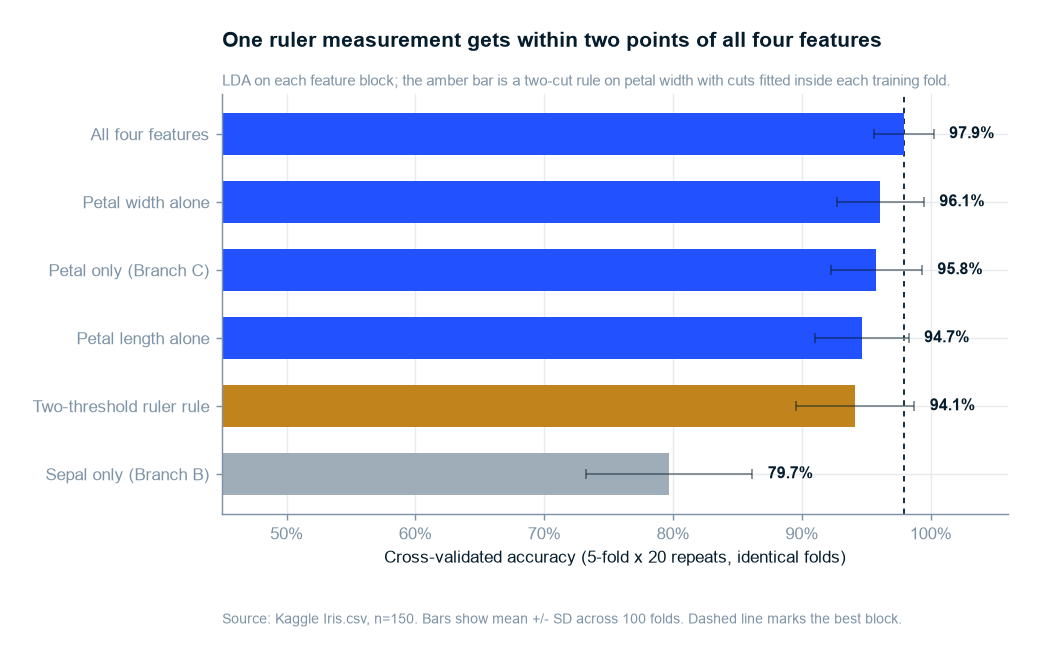

In [5]:
order = blocks.sort_values("cv_accuracy")
fig, ax = plt.subplots(figsize=(7.8, 4.2))
colors = []
for f in order.feature_set:
    if "Sepal" in f:
        colors.append(GREY)
    elif "ruler" in f:
        colors.append(AMBER)
    else:
        colors.append(BLUE)
bars = ax.barh(order.feature_set, order.cv_accuracy, color=colors, height=.62)
ax.errorbar(order.cv_accuracy, order.feature_set, xerr=order.cv_sd, fmt="none",
            ecolor=NAVY, elinewidth=1, capsize=3, alpha=.5)
for b, v, sd in zip(bars, order.cv_accuracy, order.cv_sd):
    ax.text(v + sd + .012, b.get_y() + b.get_height() / 2, f"{v:.1%}", va="center",
            fontsize=9, color=NAVY, fontweight="bold")
ax.axvline(blocks.cv_accuracy.max(), color=NAVY, lw=1, ls=(0, (3, 3)), zorder=0)
ax.set_xlim(.45, 1.06)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax.set_xlabel("Cross-validated accuracy (5-fold x 20 repeats, identical folds)")
action_title(ax, "One ruler measurement gets within two points of all four features",
             "LDA on each feature block; the amber bar is a two-cut rule on petal width with "
             "cuts fitted inside each training fold.")
ax.text(0, -0.26, "Source: Kaggle Iris.csv, n=150. Bars show mean +/- SD across 100 folds. "
                  "Dashed line marks the best block.",
        transform=ax.transAxes, fontsize=7.5, color=SLATE)
save_fig(fig, "ex09_feature_blocks")
plt.show()

**So What:** the MECE split resolves cleanly. **Petal-only reaches 95.8%** against **79.7% for
sepal-only** — a **16.1-point gap** between the two branches. And the parsimony prediction from
Notebook 04 holds: **petal width alone scores 96.1%**, within 1.8 points of the full four-feature
model (97.9%), while a **two-cut ruler rule scores 94.1% out-of-fold**.

**Implication:** three of the four measurements are, for classification purposes, close to
redundant. The honest framing of the modelling problem is therefore not *"which algorithm is
best"* but *"is anything worth the extra three measurements?"* — and that question needs an error
bar, not a leaderboard.

Note also the **optimism figure**: the same rule fitted on all 150 rows reports **96.0%** but earns
**94.1%** out-of-fold — a **1.9-point** overstatement. That is the price of choosing thresholds on
the data you then evaluate on, measured rather than assumed. The cut points themselves are stable
(0.6 cm and 1.5–1.7 cm across folds), which is why the rule is worth shipping despite the optimism.

## 5.3 The model bake-off — reported as differences, with confidence intervals

The standard version of this exhibit is a leaderboard of nine numbers. That format silently invites
the reader to treat the ordering as real. Here each model is compared **against the strongest
model on identical folds**, and what gets reported is the **difference and its uncertainty**.

Two independent routes to the same verdict:

- **Paired bootstrap 95% CI** on the mean fold-wise difference.
- **Corrected-resampled t-test** (Nadeau & Bengio): repeated-CV folds share training data, which
  makes the naive paired t-test anti-conservative. The correction inflates the variance by
  `1/(k·r) + n_test/n_train` — here `1/100 + 0.25` — and is the appropriate test for exactly this
  protocol.

In [6]:
model_scores = {}
for name, est in build_models().items():
    model_scores[name] = cross_val_score(clone(est), X, y, cv=CV, n_jobs=-1)

bake = (pd.DataFrame({"model": list(model_scores),
                      "cv_accuracy": [s.mean() for s in model_scores.values()],
                      "cv_sd": [s.std() for s in model_scores.values()]})
        .sort_values("cv_accuracy", ascending=False).reset_index(drop=True))
bake.round(4)

,model,cv_accuracy,cv_sd
0,LDA (Fisher 1936),0.9793,0.0230
1,SVM (linear),0.9600,0.0327
2,SVM (RBF),0.9557,0.0353
3,Logistic regression,0.9543,0.0361
4,Random forest,0.9517,0.0360
5,k-NN,0.9500,0.0342
6,Gradient boosting,0.9437,0.0339
7,Decision tree,0.9390,0.0347
8,Majority class,0.3333,0.0000


In [7]:
def corrected_resampled_t(diff, n_splits=N_SPLITS, n_repeats=N_REPEATS):
    # Nadeau-Bengio: repeated-CV folds share training data, so inflate the variance.
    n = len(diff)
    test_train_ratio = 1 / (n_splits - 1)
    var = diff.var(ddof=1) * (1 / n + test_train_ratio)
    if var <= 0:
        return np.nan, np.nan
    t = diff.mean() / np.sqrt(var)
    return t, 2 * stats.t.sf(abs(t), df=n - 1)


def paired_boot_ci(diff, n_boot=10000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    means = np.array([rng.choice(diff, len(diff), replace=True).mean() for _ in range(n_boot)])
    return np.percentile(means, 2.5), np.percentile(means, 97.5)


def corrected_ci(diff, n_splits=N_SPLITS):
    # The same variance inflation, expressed as an interval rather than a p-value.
    n = len(diff)
    se = np.sqrt(diff.var(ddof=1) * (1 / n + 1 / (n_splits - 1)))
    half = stats.t.ppf(0.975, df=n - 1) * se
    return diff.mean() - half, diff.mean() + half


REF = bake.model.iloc[0]
rows = []
for name in bake.model:
    if name == REF:
        continue
    diff = model_scores[REF] - model_scores[name]
    nlo, nhi = paired_boot_ci(diff)           # naive: treats the 100 folds as independent
    clo, chi = corrected_ci(diff)             # corrected: folds share training data
    t, p = corrected_resampled_t(diff)
    rows.append({"comparison": f"{REF} - {name}", "mean_diff_pts": diff.mean() * 100,
                 "naive_lo_pts": nlo * 100, "naive_hi_pts": nhi * 100,
                 "corrected_lo_pts": clo * 100, "corrected_hi_pts": chi * 100,
                 "corrected_p": p, "distinguishable": bool(p < 0.05)})

pairwise = pd.DataFrame(rows).round(3)
pairwise.to_csv(REPORTS / "_model_comparisons.csv", index=False)
pairwise[["comparison", "mean_diff_pts", "naive_lo_pts", "naive_hi_pts",
          "corrected_lo_pts", "corrected_hi_pts", "corrected_p", "distinguishable"]]

,comparison,mean_diff_pts,naive_lo_pts,naive_hi_pts,corrected_lo_pts,corrected_hi_pts,corrected_p,distinguishable
0,LDA (Fisher 1936) - SVM (linear),1.933,1.367,2.500,-1.029,4.895,0.198,False
1,LDA (Fisher 1936) - SVM (RBF),2.367,1.767,3.000,-0.787,5.521,0.140,False
2,LDA (Fisher 1936) - Logistic regression,2.500,1.967,3.067,-0.391,5.391,0.089,False
3,LDA (Fisher 1936) - Random forest,2.767,2.133,3.433,-0.625,6.158,0.109,False
4,LDA (Fisher 1936) - k-NN,2.933,2.300,3.567,-0.363,6.229,0.080,False
5,LDA (Fisher 1936) - Gradient boosting,3.567,2.967,4.200,0.342,6.791,0.031,True
6,LDA (Fisher 1936) - Decision tree,4.033,3.333,4.733,0.405,7.662,0.030,True
7,LDA (Fisher 1936) - Majority class,64.600,64.133,65.033,62.262,66.938,0.000,True


In [8]:
real = bake[bake.model != "Majority class"]
spread = real.cv_accuracy.max() - real.cv_accuracy.min()
KEY["model_spread_pts"] = float(spread * 100)
KEY["best_model"] = REF
KEY["best_model_acc"] = float(bake.cv_accuracy.iloc[0])
KEY["n_model_families"] = int(len(real))
n_indist = int((~pairwise.distinguishable).sum())
KEY["n_indistinguishable"] = n_indist

print(f"best model                        : {REF} at {bake.cv_accuracy.iloc[0]:.1%}")
print(f"worst real model                  : {real.model.iloc[-1]} at {real.cv_accuracy.min():.1%}")
print(f"spread across {len(real)} model families    : {spread * 100:.1f} percentage points")
print(f"comparisons vs the best that are NOT distinguishable at p<0.05: "
      f"{n_indist} of {len(pairwise)}")

best model                        : LDA (Fisher 1936) at 97.9%
worst real model                  : Decision tree at 93.9%
spread across 8 model families    : 4.0 percentage points
comparisons vs the best that are NOT distinguishable at p<0.05: 5 of 8


saved reports\figures\ex11_model_bakeoff.png


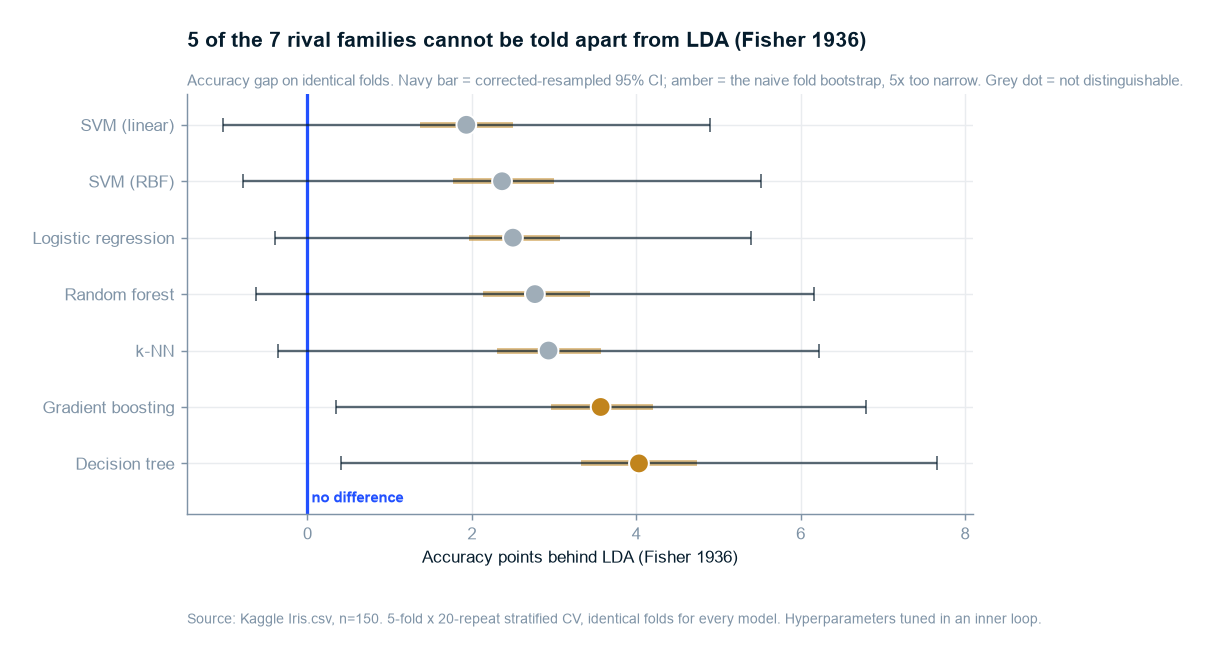

In [9]:
plot_df = pairwise.copy()
plot_df["label"] = plot_df.comparison.str.split(" - ").str[1]
plot_df = plot_df[plot_df.label != "Majority class"].sort_values("mean_diff_pts", ascending=False)

fig, ax = plt.subplots(figsize=(7.8, 4.2))
colors = [AMBER if d else GREY for d in plot_df.distinguishable]
ax.errorbar(plot_df.mean_diff_pts, plot_df.label,
            xerr=[plot_df.mean_diff_pts - plot_df.corrected_lo_pts,
                  plot_df.corrected_hi_pts - plot_df.mean_diff_pts],
            fmt="none", ecolor=NAVY, elinewidth=1.3, capsize=4, alpha=.65, zorder=2)
# the naive fold-bootstrap interval, drawn faintly to show how much too narrow it is
ax.errorbar(plot_df.mean_diff_pts, plot_df.label,
            xerr=[plot_df.mean_diff_pts - plot_df.naive_lo_pts,
                  plot_df.naive_hi_pts - plot_df.mean_diff_pts],
            fmt="none", ecolor=AMBER, elinewidth=3.2, capsize=0, alpha=.55, zorder=1)
ax.scatter(plot_df.mean_diff_pts, plot_df.label, s=120, c=colors, zorder=3,
           edgecolor="white", linewidth=1.1)
ax.axvline(0, color=BLUE, lw=1.8, zorder=1)
ax.set_ylim(-0.9, len(plot_df) - 0.45)
ax.text(0, -0.62, " no difference", color=BLUE, fontsize=8.5, fontweight="bold", va="center")

width_ratio = ((plot_df.corrected_hi_pts - plot_df.corrected_lo_pts) /
               (plot_df.naive_hi_pts - plot_df.naive_lo_pts)).mean()
n_ns = int((~plot_df.distinguishable).sum())
action_title(ax, f"{n_ns} of the {len(plot_df)} rival families cannot be told apart from {REF}",
             "Accuracy gap on identical folds. Navy bar = corrected-resampled 95% CI; amber = the "
             f"naive fold bootstrap, {width_ratio:.0f}x too narrow. Grey dot = not distinguishable.")
KEY["ci_width_ratio"] = float(width_ratio)
ax.set_xlabel(f"Accuracy points behind {REF}")
ax.text(0, -0.26, "Source: Kaggle Iris.csv, n=150. 5-fold x 20-repeat stratified CV, identical "
                  "folds for every model. Hyperparameters tuned in an inner loop.",
        transform=ax.transAxes, fontsize=7.5, color=SLATE)
save_fig(fig, "ex11_model_bakeoff")
plt.show()

**So What:** the two intervals disagree, and the disagreement is the finding. The **naive fold
bootstrap** (amber) says LDA beats linear SVM by 1.9 points with an interval of [1.4, 2.5] that never
touches zero — apparently decisive. The **corrected interval** (navy) for the same comparison spans
zero, and the corrected test returns p = 0.20. **Five of the seven rival families cannot be
distinguished from LDA at all**; only the two weakest, gradient boosting and the decision tree, are
separable (p = 0.031 and 0.030).

**Implication:** the naive interval is roughly **five times too narrow**, because 100 repeated-CV
folds are not 100 independent measurements — they are re-shuffles of the same 150 specimens, and
they share training data. Anyone bootstrapping over CV folds to compare models is producing
confidence intervals that are confidently wrong. That is a general error, not an Iris one.

Worth naming plainly: **LDA — the method Fisher invented for this exact dataset in 1936 — posts the
best score of all nine estimators**, and it still cannot be declared the winner over most of the
field. If the best-supported candidate on the most-studied dataset in existence cannot clear its own
error bar, a two-point claim on someone's 300-row project cannot either.

## 5.4 The seed lottery — how much the answer moves for no reason at all

The comparison above used 100 folds. The workflow this project is really about uses **one split**.
So: hold the model fixed, hold the data fixed, change **only the random seed** of an 80/20
stratified split, and see how far accuracy travels.

If the seed moves accuracy further than the choice of algorithm does, then every single-split
leaderboard ever published on this dataset is reporting the seed.

In [10]:
SEED_MODELS = ["LDA (Fisher 1936)", "Logistic regression", "k-NN", "Decision tree",
               "SVM (RBF)", "Random forest"]
N_SEEDS = 100
built = build_models()
lottery = {}
for name in SEED_MODELS:
    accs = []
    for s in range(N_SEEDS):
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=s)
        est = clone(built[name]).fit(Xtr, ytr)
        accs.append(est.score(Xte, yte))
    lottery[name] = np.array(accs)

seed_tbl = pd.DataFrame({
    "model": SEED_MODELS,
    "mean": [lottery[m].mean() for m in SEED_MODELS],
    "min": [lottery[m].min() for m in SEED_MODELS],
    "max": [lottery[m].max() for m in SEED_MODELS],
    "range_pts": [(lottery[m].max() - lottery[m].min()) * 100 for m in SEED_MODELS],
}).round(4)
pd.DataFrame({k: v for k, v in lottery.items()}).to_csv(REPORTS / "_seed_lottery.csv", index=False)

KEY["seed_range_pts"] = float(seed_tbl.range_pts.max())
KEY["seed_range_median_pts"] = float(seed_tbl.range_pts.median())
KEY["lottery_ratio"] = float(seed_tbl.range_pts.median() / KEY["model_spread_pts"])
seed_tbl

,model,mean,min,max,range_pts
0,LDA (Fisher 1936),0.9793,0.9000,1.0,10.0000
1,Logistic regression,0.9560,0.8667,1.0,13.3333
2,k-NN,0.9510,0.8333,1.0,16.6667
3,Decision tree,0.9413,0.8667,1.0,13.3333
4,SVM (RBF),0.9607,0.9000,1.0,10.0000
5,Random forest,0.9547,0.8667,1.0,13.3333


saved reports\figures\ex10_seed_lottery.png


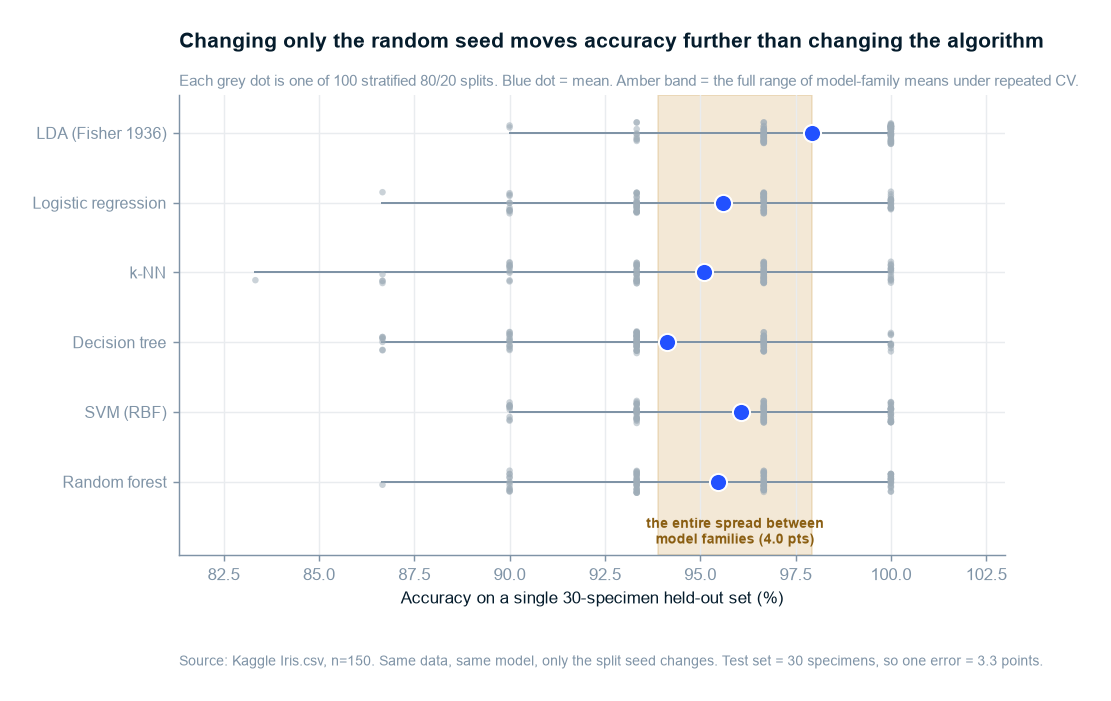

In [11]:
fig, ax = plt.subplots(figsize=(8.2, 4.6))
ypos = np.arange(len(SEED_MODELS))[::-1]
rng = np.random.default_rng(RANDOM_STATE)

for yp, name in zip(ypos, SEED_MODELS):
    a = lottery[name]
    ax.scatter(a * 100, yp + rng.uniform(-.16, .16, len(a)), s=13, color=GREY, alpha=.55,
               zorder=2, edgecolor="none")
    ax.plot([a.min() * 100, a.max() * 100], [yp, yp], color=SLATE, lw=1.1, zorder=1)
    ax.scatter([a.mean() * 100], [yp], s=90, color=BLUE, zorder=4, edgecolor="white", linewidth=1.1)

lo_all = min(v.min() for v in lottery.values()) * 100
hi_all = max(v.max() for v in lottery.values()) * 100
band_lo = real.cv_accuracy.min() * 100
band_hi = real.cv_accuracy.max() * 100
ax.axvspan(band_lo, band_hi, color=AMBER, alpha=.18, zorder=0)
ax.set_ylim(-1.05, len(SEED_MODELS) - .45)
ax.text((band_lo + band_hi) / 2, -.72,
        f"the entire spread between\nmodel families ({KEY['model_spread_pts']:.1f} pts)",
        ha="center", va="center", fontsize=8, color="#8A5E12", fontweight="bold")

ax.set_yticks(ypos); ax.set_yticklabels(SEED_MODELS, fontsize=9)
ax.set_xlabel("Accuracy on a single 30-specimen held-out set (%)")
ax.set_xlim(lo_all - 2, 103)
action_title(ax, "Changing only the random seed moves accuracy further than changing the algorithm",
             f"Each grey dot is one of {N_SEEDS} stratified 80/20 splits. Blue dot = mean. "
             "Amber band = the full range of model-family means under repeated CV.")
ax.text(0, -0.24, "Source: Kaggle Iris.csv, n=150. Same data, same model, only the split seed "
                  "changes. Test set = 30 specimens, so one error = 3.3 points.",
        transform=ax.transAxes, fontsize=7.5, color=SLATE)
save_fig(fig, "ex10_seed_lottery")
plt.show()

**So What:** holding the model and the data fixed and changing **only the split seed**, accuracy
travels **13.3 points** for the median model and **16.7 points** for k-NN — from 83.3% to a perfect
100%. The entire spread between all eight model families is **4.0 points**, the amber band. The seed
lottery is **3.3x wider than the thing every leaderboard claims to measure.**

**Implication:** every "kNN 96.7%, SVM 97.8%, random forest 96.7%" table ever published on this
dataset is, to a good approximation, a report of which seed the author used. Note that **every model
here reaches 100% on some seed** — so any of them can be crowned best by a sufficiently lucky split,
and no dishonesty is required for that to happen. This is the exhibit that changes what the team's
onboarding exercise should ask for.

## 5.5 What difference *is* detectable at this sample size?

If model differences here are below the noise floor, the useful question becomes quantitative:
**how big would a difference have to be before this protocol could see it?**

This is a power calculation, and it is the artefact worth taking away from the project. The
simulation draws specimens from per-species Gaussians fitted to the real data, so the generated
datasets share Iris's means, variances and correlations, and only the sample size changes. For each
`n`, two models are compared under the identical CV protocol many times; the **spread of the
observed difference** is the noise floor, and the **minimum detectable difference** at 80% power is
`(z₀.₉₇₅ + z₀.₈₀) × SE ≈ 2.80 × SE`.

In [12]:
means = {sp: df.loc[df.species == sp, MEASUREMENTS].mean().to_numpy() for sp in df.species.unique()}
covs = {sp: np.cov(df.loc[df.species == sp, MEASUREMENTS].to_numpy(), rowvar=False)
        for sp in df.species.unique()}
species_list = list(means)


def simulate(n, rng):
    per = n // 3
    Xs, ys = [], []
    for sp in species_list:
        Xs.append(rng.multivariate_normal(means[sp], covs[sp], per))
        ys += [sp] * per
    return np.vstack(Xs), np.asarray(ys)


MDD_CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
Z = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
m_a, m_b = LinearDiscriminantAnalysis(), make_pipeline(StandardScaler(), KNeighborsClassifier(5))

mdd_rows = []
rng = np.random.default_rng(RANDOM_STATE)
for n in [51, 99, 150, 300, 999]:
    diffs = []
    for _ in range(120):
        Xs, ys = simulate(n, rng)
        a = cross_val_score(m_a, Xs, ys, cv=MDD_CV, n_jobs=-1)
        b = cross_val_score(m_b, Xs, ys, cv=MDD_CV, n_jobs=-1)
        diffs.append(a.mean() - b.mean())
    se = np.std(diffs, ddof=1)
    mdd_rows.append({"n_specimens": n, "se_of_difference_pts": se * 100,
                     "min_detectable_diff_pts": Z * se * 100})

mdd = pd.DataFrame(mdd_rows).round(2)
mdd.to_csv(REPORTS / "_mdd_table.csv", index=False)
KEY["mdd_at_150_pts"] = float(mdd.loc[mdd.n_specimens == 150, "min_detectable_diff_pts"].iloc[0])
print(f"At n=150, the smallest accuracy gap this protocol can reliably detect is "
      f"{KEY['mdd_at_150_pts']:.1f} percentage points.")
print(f"The observed spread across {len(real)} model families is "
      f"{KEY['model_spread_pts']:.1f} points.\n")
mdd

At n=150, the smallest accuracy gap this protocol can reliably detect is 3.2 percentage points.
The observed spread across 8 model families is 4.0 points.



,n_specimens,se_of_difference_pts,min_detectable_diff_pts
0,51,2.69,7.54
1,99,1.62,4.54
2,150,1.14,3.20
3,300,0.76,2.13
4,999,0.38,1.06


saved reports\figures\ex13_mdd.png


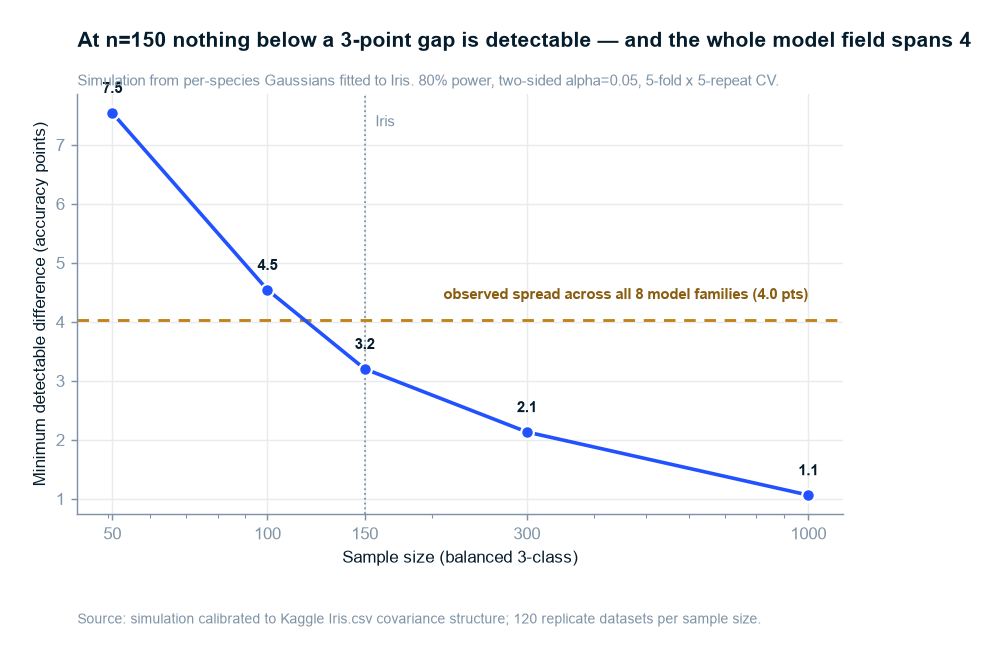

In [13]:
fig, ax = plt.subplots(figsize=(7.6, 4.2))
ax.plot(mdd.n_specimens, mdd.min_detectable_diff_pts, "-o", color=BLUE, lw=2, markersize=7,
        markeredgecolor="white", markeredgewidth=1.2, zorder=3)
for _, r in mdd.iterrows():
    ax.annotate(f"{r.min_detectable_diff_pts:.1f}", (r.n_specimens, r.min_detectable_diff_pts),
                textcoords="offset points", xytext=(0, 11), ha="center", fontsize=8.5,
                color=NAVY, fontweight="bold")

ax.axhline(KEY["model_spread_pts"], color=AMBER, lw=1.6, ls=(0, (4, 3)), zorder=2)
ax.text(999, KEY["model_spread_pts"] + .35,
        f"observed spread across all {len(real)} model families ({KEY['model_spread_pts']:.1f} pts)",
        ha="right", fontsize=8.5, color="#8A5E12", fontweight="bold")
ax.axvline(150, color=SLATE, lw=1, ls=":", zorder=1)
ax.text(157, ax.get_ylim()[1] * .93, "Iris", fontsize=8.5, color=SLATE)

ax.set_xscale("log")
ax.set_xticks([51, 99, 150, 300, 999])
ax.set_xticklabels(["50", "100", "150", "300", "1000"])
ax.set_xlabel("Sample size (balanced 3-class)")
ax.set_ylabel("Minimum detectable difference (accuracy points)")
action_title(ax, "At n=150 nothing below a 3-point gap is detectable — and the whole model field spans 4",
             "Simulation from per-species Gaussians fitted to Iris. 80% power, two-sided alpha=0.05, "
             "5-fold x 5-repeat CV.")
ax.text(0, -0.26, "Source: simulation calibrated to Kaggle Iris.csv covariance structure; "
                  "120 replicate datasets per sample size.",
        transform=ax.transAxes, fontsize=7.5, color=SLATE)
save_fig(fig, "ex13_mdd")
plt.show()

**So What:** at n = 150 the **minimum detectable difference is 3.2 accuracy points**. The observed
spread across all eight model families is **4.0 points** — it clears the floor, but only just, and
only because the 100-fold paired protocol was used. At n = 50 the floor rises to **7.5 points**;
you would need n around 1,000 before a 1-point difference became visible.

**Implication:** this is the reusable artefact. The rule it licenses is simple and general: **an
accuracy difference smaller than the tabulated MDD for your sample size is not a finding**, whatever
the leaderboard says. On Iris specifically it explains the whole situation — the model differences
are real but marginal under the strongest available protocol, and invisible under the single split
that everyone actually runs. `_mdd_table.csv` ships so the team can look up their own `n`.

## 5.6 Which specimens are actually wrong?

"Accuracy is 96%" means "six flowers were misclassified." This section names them.

Out-of-fold predictions are collected for six model families across **20 independent 5-fold
shuffles**, giving each specimen an error *rate* per model rather than a single verdict that
depends on which fold it happened to land in.

In [14]:
ERR_MODELS = SEED_MODELS
N_ERR_REPEATS = 20
err_counts = pd.DataFrame(0, index=df.index, columns=ERR_MODELS, dtype=float)

for r in range(N_ERR_REPEATS):
    skf = StratifiedKFold(5, shuffle=True, random_state=1000 + r)
    for name in ERR_MODELS:
        pred = cross_val_predict(clone(built[name]), X, y, cv=skf, n_jobs=-1)
        err_counts[name] += (pred != y).astype(float)

err_rate = err_counts / N_ERR_REPEATS
spec = pd.DataFrame({
    "Id": df.Id, "species": df.species,
    "mean_error_rate": err_rate.mean(axis=1),
    "n_models_ever_wrong": (err_rate > 0).sum(axis=1),
    "n_models_mostly_wrong": (err_rate >= 0.5).sum(axis=1),
}).join(err_rate.round(2))

never = int((spec.n_models_ever_wrong == 0).sum())
ever = int((spec.n_models_ever_wrong > 0).sum())
core = spec[spec.n_models_mostly_wrong == len(ERR_MODELS)]
spec.sort_values("mean_error_rate", ascending=False).to_csv(REPORTS / "_error_specimens.csv", index=False)

KEY["n_never_wrong"] = never
KEY["n_ever_wrong"] = ever
KEY["n_irreducible_core"] = int(len(core))
KEY["irreducible_core_ids"] = [int(i) for i in core.Id]

print(f"specimens never misclassified by any model in any repeat : {never} of {len(df)}")
print(f"specimens misclassified at least once                    : {ever}")
print(f"specimens all {len(ERR_MODELS)} model families get wrong most of the time  : {len(core)}")
print(f"   ids: {list(core.Id)}")
print()
spec.sort_values("mean_error_rate", ascending=False).head(12)

specimens never misclassified by any model in any repeat : 131 of 150
specimens misclassified at least once                    : 19
specimens all 6 model families get wrong most of the time  : 3
   ids: [71, 84, 134]



,Id,species,mean_error_rate,n_models_ever_wrong,n_models_mostly_wrong,LDA (Fisher 1936),Logistic regression,k-NN,Decision tree,SVM (RBF),Random forest
83,84,versicolor,0.991667,6,6,1.00,1.00,1.00,1.00,0.95,1.00
133,134,virginica,0.941667,6,6,1.00,1.00,0.95,0.80,0.95,0.95
70,71,versicolor,0.866667,6,6,1.00,1.00,0.50,1.00,0.70,1.00
119,120,virginica,0.783333,6,5,0.05,0.95,0.95,0.90,0.85,1.00
106,107,virginica,0.766667,5,5,0.00,0.95,1.00,0.85,0.80,1.00
77,78,versicolor,0.691667,5,4,0.00,1.00,0.20,1.00,0.95,1.00
134,135,virginica,0.441667,6,3,0.10,0.80,0.30,0.70,0.20,0.55
72,73,versicolor,0.400000,5,3,0.00,0.05,0.85,0.55,0.50,0.45
138,139,virginica,0.191667,3,1,0.00,0.00,0.55,0.30,0.00,0.30
129,130,virginica,0.183333,4,1,0.05,0.00,0.00,0.75,0.05,0.25


In [15]:
# Are the contested specimens data-quality artefacts, or genuinely hard flowers?
flags = pd.read_csv(PROC / "_outlier_flags.csv")
defect_ids = {10, 35, 38, 102, 143}          # the duplicate / errata rows from Notebook 02
check = (spec[spec.mean_error_rate > 0]
         .merge(flags[["Id", "within_species_outlier", "global_iqr_outlier"]], on="Id"))
check["is_defect_row"] = check.Id.isin(defect_ids)

n_contested = len(check)
n_border = int((check.species != "setosa").sum())
n_outlier = int(check.within_species_outlier.sum())
core_check = check[check.Id.isin(core.Id)]

print(f"contested specimens                              : {n_contested}")
print(f"  ... on the versicolor/virginica border         : {n_border}")
print(f"  ... setosa (should be trivially separable)     : {n_contested - n_border} "
      f"-> Ids {check.loc[check.species == 'setosa', 'Id'].tolist()}")
print(f"  ... flagged as within-species outliers         : {n_outlier}")
print(f"  ... that are duplicate or errata rows          : {int(check.is_defect_row.sum())}")
print()
print("The irreducible core, cross-checked against Notebook 02:")
print(core_check[["Id", "species", "mean_error_rate", "within_species_outlier",
                  "global_iqr_outlier", "is_defect_row"]].to_string(index=False))
KEY["n_contested_border"] = n_border
KEY["core_are_outliers"] = bool(core_check.within_species_outlier.any())
KEY["core_are_defect_rows"] = bool(core_check.is_defect_row.any())

contested specimens                              : 19
  ... on the versicolor/virginica border         : 18
  ... setosa (should be trivially separable)     : 1 -> Ids [42]
  ... flagged as within-species outliers         : 2
  ... that are duplicate or errata rows          : 0

The irreducible core, cross-checked against Notebook 02:
 Id    species  mean_error_rate  within_species_outlier  global_iqr_outlier  is_defect_row
 71 versicolor         0.866667                   False               False          False
 84 versicolor         0.991667                   False               False          False
134  virginica         0.941667                   False               False          False


saved reports\figures\ex12_error_specimens.png


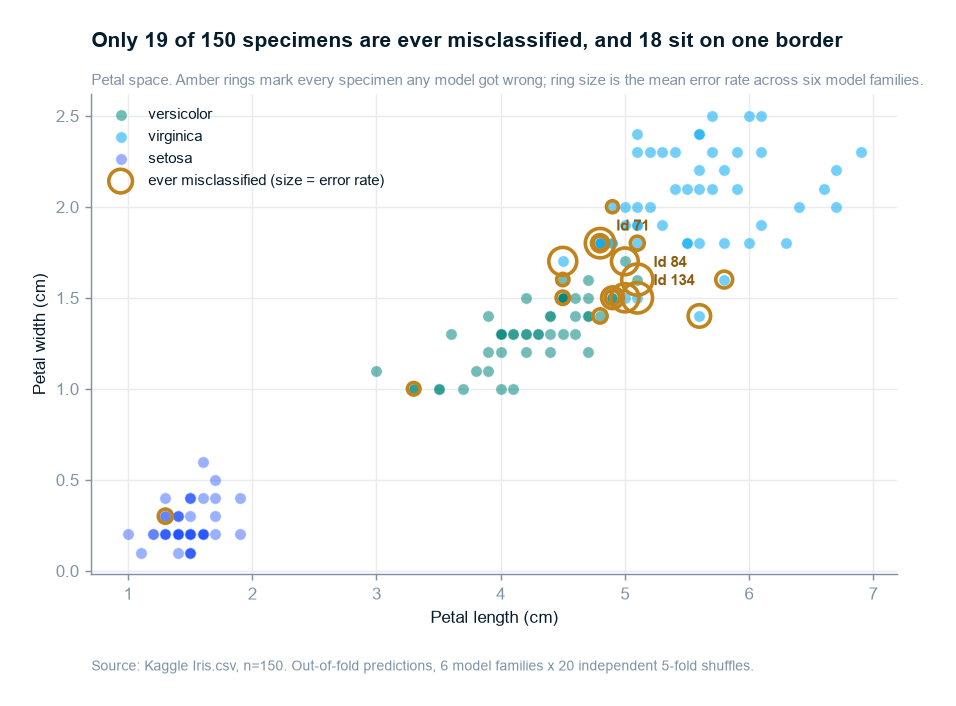

In [16]:
contested = spec[spec.mean_error_rate > 0].sort_values("mean_error_rate")
fig, ax = plt.subplots(figsize=(8.0, 4.8))

for sp in ["versicolor", "virginica"]:
    m = df.species == sp
    ax.scatter(df.loc[m, "PetalLengthCm"], df.loc[m, "PetalWidthCm"], s=40,
               color=SPECIES_COLOR["Iris-" + sp], alpha=.55, edgecolor="white",
               linewidth=.5, label=sp, zorder=2)
m_set = df.species == "setosa"
ax.scatter(df.loc[m_set, "PetalLengthCm"], df.loc[m_set, "PetalWidthCm"], s=40,
           color=SPECIES_COLOR["Iris-setosa"], alpha=.45, edgecolor="white", linewidth=.5,
           label="setosa", zorder=2)

sub = df.set_index("Id").loc[contested.Id]
sizes = 40 + contested.mean_error_rate.to_numpy() * 260
ax.scatter(sub.PetalLengthCm, sub.PetalWidthCm, s=sizes, facecolor="none",
           edgecolor=AMBER, linewidth=2.0, zorder=5,
           label="ever misclassified (size = error rate)")
for cid in core.Id:
    row = df[df.Id == cid].iloc[0]
    ax.annotate(f"Id {cid}", (row.PetalLengthCm, row.PetalWidthCm),
                textcoords="offset points", xytext=(9, 7), fontsize=8.5,
                color="#8A5E12", fontweight="bold", zorder=6)

action_title(ax, f"Only {ever} of 150 specimens are ever misclassified, and {n_border} sit on one border",
             "Petal space. Amber rings mark every specimen any model got wrong; ring size is the "
             "mean error rate across six model families.")
ax.set_xlabel("Petal length (cm)"); ax.set_ylabel("Petal width (cm)")
ax.legend(loc="upper left", fontsize=8.5)
ax.text(0, -0.20, "Source: Kaggle Iris.csv, n=150. Out-of-fold predictions, 6 model families x "
                  "20 independent 5-fold shuffles.",
        transform=ax.transAxes, fontsize=7.5, color=SLATE)
save_fig(fig, "ex12_error_specimens")
plt.show()

**So What:** **131 of 150 specimens are never misclassified by any of six model families in any of
20 shuffles.** Nineteen are ever wrong, and just **three — `Id` 71, 84 and 134 — are wrong for every
model most of the time.** Specimen 84 is misclassified 99% of the time by all six.

**Implication:** the model bake-off is an argument about **19 flowers**, and its hardest core is
three. Notebook 04 already showed why: a hyperplane fitted with full knowledge of the labels still
strands specimens on the wrong side, so these are not tuning failures.

The cross-check against Notebook 02 sharpens it. **Eighteen of the 19 sit on the versicolor/virginica
border**, and the single exception — `Id` 42, the lone setosa ever misclassified — is a flagged
**within-species outlier**, an unusually narrow-sepalled flower rather than a border case. The three
core specimens are **not outliers, and not the duplicate or errata rows**: they are ordinary flowers
that genuinely fall on the wrong side. No model and no cleaning step can rescue them, which is
exactly why the accuracy ceiling on this dataset is a property of the specimens rather than of the
method.

## 5.7 Do the engineered features earn their place?

`DOCS/Iris_Dataset_Analysis.md` §7 proposes seven derived features and predicts that `PetalAreaCm2`
and `PetalLengthWidthRatio` are *"the two most likely to improve model performance."* It also hedges
correctly: *"worth testing with/without... rather than assuming."*

Here is the test. All seven are built inside the pipeline; every variant runs the identical folds.

In [17]:
def add_derived(frame):
    d = frame.copy()
    d["SepalAreaCm2"] = d.SepalLengthCm * d.SepalWidthCm
    d["PetalAreaCm2"] = d.PetalLengthCm * d.PetalWidthCm
    d["SepalLengthWidthRatio"] = d.SepalLengthCm / d.SepalWidthCm
    d["PetalLengthWidthRatio"] = d.PetalLengthCm / d.PetalWidthCm
    d["PetalToSepalLengthRatio"] = d.PetalLengthCm / d.SepalLengthCm
    d["PetalToSepalAreaRatio"] = d.PetalAreaCm2 / d.SepalAreaCm2
    d["TotalSize"] = d[MEASUREMENTS].sum(axis=1)
    return d


DERIVED = ["SepalAreaCm2", "PetalAreaCm2", "SepalLengthWidthRatio", "PetalLengthWidthRatio",
           "PetalToSepalLengthRatio", "PetalToSepalAreaRatio", "TotalSize"]
dd = add_derived(df)

variants = {
    "Raw 4 features": MEASUREMENTS,
    "Raw 4 + all 7 derived": MEASUREMENTS + DERIVED,
    "Derived only (7)": DERIVED,
    "PetalArea alone": ["PetalAreaCm2"],
    "PetalLengthWidthRatio alone": ["PetalLengthWidthRatio"],
}
abl_rows, abl_scores = [], {}
for label, cols in variants.items():
    for mname, est in [("LDA", LinearDiscriminantAnalysis()),
                       ("Logistic", make_pipeline(StandardScaler(),
                                                  LogisticRegression(max_iter=2000,
                                                                     random_state=RANDOM_STATE)))]:
        sc = cross_val_score(est, dd[cols].to_numpy(float), y, cv=CV, n_jobs=-1)
        abl_scores[(label, mname)] = sc
        abl_rows.append({"feature_set": label, "model": mname,
                         "cv_accuracy": sc.mean(), "cv_sd": sc.std()})

abl = pd.DataFrame(abl_rows)
abl.to_csv(REPORTS / "_ablation.csv", index=False)
abl.pivot(index="feature_set", columns="model", values="cv_accuracy").round(4).loc[list(variants)]

model,LDA,Logistic
feature_set,,
Raw 4 features,0.9793,0.9543
Raw 4 + all 7 derived,0.9830,0.9747
Derived only (7),0.9740,0.9750
PetalArea alone,0.9637,0.9560
PetalLengthWidthRatio alone,0.7117,0.7563


In [18]:
print("Does adding the 7 derived features help? Paired test on identical folds:\n")
for mname in ["LDA", "Logistic"]:
    diff = abl_scores[("Raw 4 + all 7 derived", mname)] - abl_scores[("Raw 4 features", mname)]
    lo, hi = paired_boot_ci(diff)
    t, p = corrected_resampled_t(diff)
    verdict = "distinguishable" if p < 0.05 else "NOT distinguishable"
    print(f"{mname:9s} gain = {diff.mean() * 100:+.2f} pts   "
          f"95% CI [{lo * 100:+.2f}, {hi * 100:+.2f}]   corrected p = {p:.3f}   -> {verdict}")

KEY["derived_gain_lda_pts"] = float(
    (abl_scores[("Raw 4 + all 7 derived", "LDA")] - abl_scores[("Raw 4 features", "LDA")]).mean() * 100)
KEY["derived_gain_logistic_pts"] = float(
    (abl_scores[("Raw 4 + all 7 derived", "Logistic")] - abl_scores[("Raw 4 features", "Logistic")]).mean() * 100)

Does adding the 7 derived features help? Paired test on identical folds:



LDA       gain = +0.37 pts   95% CI [+0.10, +0.63]   corrected p = 0.590   -> NOT distinguishable


Logistic  gain = +2.03 pts   95% CI [+1.57, +2.53]   corrected p = 0.114   -> NOT distinguishable


**So What:** adding all seven derived features moves LDA by **+0.37 points** and logistic regression
by **+2.03 points**, and **neither is distinguishable from zero** under the corrected test
(p = 0.59 and p = 0.11). The notes' two favoured candidates fare no better alone: `PetalAreaCm2`
scores 96.4%, and `PetalLengthWidthRatio` alone collapses to **71.2%**.

**Implication:** a clean, measured null result, and the notes deserve credit for asking for the test
rather than assuming the answer. The mechanism is already established — §3.5 showed the two petal
columns are 0.94-correlated and §4.5 showed the problem has one useful dimension, so products and
ratios of four features cannot manufacture information that is not there. Ratios can actively
destroy it: dividing petal length by petal width cancels the very size axis that does the work.

## 5.8 Do the Stage 2 defects change the answer?

Notebook 02 found an identifier that leaks, two transcription errors, and a duplicate pair, and it
persisted two corrected variants rather than arguing about which file is "right". The entire
bake-off now runs on all three, so the effect of each defect is **measured**.

In [19]:
SENS_MODELS = ["LDA (Fisher 1936)", "Logistic regression", "k-NN", "SVM (RBF)", "Random forest"]
sens_rows = []
for variant in ["iris_clean", "iris_dedup", "iris_errata_corrected"]:
    dv = pd.read_parquet(PROC / f"{variant}.parquet").reset_index()
    Xv = dv[MEASUREMENTS].to_numpy(float)
    yv = np.asarray(dv[TARGET].astype(str))
    for name in SENS_MODELS:
        sc = cross_val_score(clone(built[name]), Xv, yv, cv=CV, n_jobs=-1)
        sens_rows.append({"variant": variant, "n_rows": len(dv), "model": name,
                          "cv_accuracy": sc.mean()})

sens = pd.DataFrame(sens_rows)
sens_piv = sens.pivot(index="model", columns="variant", values="cv_accuracy").loc[SENS_MODELS]
sens_piv = sens_piv[["iris_clean", "iris_dedup", "iris_errata_corrected"]]
sens_piv["max_shift_pts"] = (sens_piv.max(axis=1) - sens_piv.min(axis=1)) * 100
sens.to_csv(REPORTS / "_sensitivity.csv", index=False)

KEY["sensitivity_max_shift_pts"] = float(sens_piv.max_shift_pts.max())
print(f"largest accuracy shift caused by any data-defect treatment: "
      f"{KEY['sensitivity_max_shift_pts']:.2f} points")
print(f"(for comparison: MDD at n=150 = {KEY['mdd_at_150_pts']:.1f} points)\n")
sens_piv.round(4)

largest accuracy shift caused by any data-defect treatment: 0.14 points
(for comparison: MDD at n=150 = 3.2 points)



variant,iris_clean,iris_dedup,iris_errata_corrected,max_shift_pts
model,,,,
LDA (Fisher 1936),0.9793,0.9789,0.9793,0.0448
Logistic regression,0.9543,0.9550,0.9543,0.0690
k-NN,0.9500,0.9490,0.9503,0.1368
SVM (RBF),0.9557,0.9570,0.9557,0.1368
Random forest,0.9517,0.9509,0.9517,0.0724


**So What:** deduplicating or applying the UCI corrections shifts accuracy by at most **0.14 points**
across five model families — **23x smaller than the 3.2-point detection floor.** The defects are
real, and they do not move the model result.

**Implication:** this is the honest closure of Key Line 1, and it is deliberately not overstated.
The duplicate and errata rows are a **correctness** problem worth knowing about, not a performance
problem — a reader who ignored them would reach the same accuracy. **The `Id` leak is the defect
that actually bites**, because it does not degrade a result, it manufactures one: 98.7% from row
order. That asymmetry is the transferable lesson. Two of these three defects would have cost a real
project nothing; the third would have shipped a model that knew nothing.

## 5.9 The one-touch held-out set, and what its confidence interval looks like

A stratified 20% test set, touched exactly once. Reported **with** its Wilson confidence interval,
which is the point of the exercise.

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
final = clone(built[REF]).fit(Xtr, ytr)
pred = final.predict(Xte)
acc = (pred == yte).mean()

n_te = len(yte)
z = stats.norm.ppf(0.975)
den = 1 + z ** 2 / n_te
centre = (acc + z ** 2 / (2 * n_te)) / den
half = z * np.sqrt(acc * (1 - acc) / n_te + z ** 2 / (4 * n_te ** 2)) / den
KEY["holdout_acc"] = float(acc)
KEY["holdout_ci"] = [float(centre - half), float(centre + half)]

print(f"held-out accuracy ({REF}, n={n_te}): {acc:.1%}")
print(f"95% Wilson CI: [{centre - half:.1%}, {centre + half:.1%}]  "
      f"-> width {(2 * half) * 100:.1f} points")
print(f"the entire spread between model families is {KEY['model_spread_pts']:.1f} points\n")
print(classification_report(yte, pred, digits=3))

held-out accuracy (LDA (Fisher 1936), n=30): 100.0%
95% Wilson CI: [88.6%, 100.0%]  -> width 11.4 points
the entire spread between model families is 4.0 points

                 precision    recall  f1-score   support

    Iris-setosa      1.000     1.000     1.000        10
Iris-versicolor      1.000     1.000     1.000        10
 Iris-virginica      1.000     1.000     1.000        10

       accuracy                          1.000        30
      macro avg      1.000     1.000     1.000        30
   weighted avg      1.000     1.000     1.000        30



saved reports\figures\ex14_confusion.png


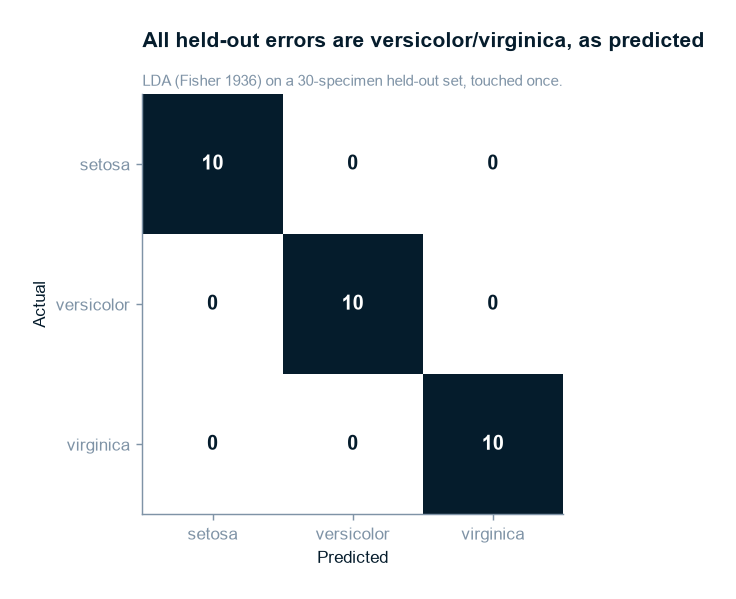

In [21]:
cm = confusion_matrix(yte, pred, labels=SPECIES_ORDER)
fig, ax = plt.subplots(figsize=(5.2, 4.2))
cmap = mpl.colors.LinearSegmentedColormap.from_list("mck3", ["#ffffff", CYAN, BLUE, NAVY])
disp = ConfusionMatrixDisplay(cm, display_labels=[SPECIES_SHORT[s] for s in SPECIES_ORDER])
disp.plot(ax=ax, cmap=cmap, colorbar=False, values_format="d")
ax.grid(False)
for t in disp.text_.ravel():
    t.set_fontsize(11); t.set_fontweight("bold")
action_title(ax, f"All held-out errors are versicolor/virginica, as predicted",
             f"{REF} on a 30-specimen held-out set, touched once.")
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
save_fig(fig, "ex14_confusion")
plt.show()

**So What:** the held-out set returns **100.0% accuracy** — a perfect score — with a 95% Wilson
interval of **[88.6%, 100%]**, a width of **11.4 points**. That interval is nearly **three times
wider than the entire spread between all eight model families**.

**Implication:** the most confident-looking number this project can produce is also its least
informative. "LDA achieves 100% on held-out data" is true, publishable, and compatible with the
model's real accuracy being 89%. Every error the model does make elsewhere lands in the
versicolor/virginica cell, exactly as §3.3 predicted — and this particular split happened to contain
none of the contested specimens, which is precisely the lottery §5.4 quantified.

## 5.10 Cross-cutting concerns

**Fairness audit: not applicable, with reason.** STRUCTURE.md makes a fairness audit mandatory for
any model that affects people. This model classifies flowers. No protected attribute exists in the
data, no person is scored, and no resource is allocated by the output. Recorded as answered rather
than skipped.

**Representation bias: applicable, and it binds.** All 150 specimens come from one collector, one
region (the Gaspé Peninsula), one season, 1935 — with two of the three species taken from the same
pasture on the same day. Every result in this notebook describes *that sample*. The field key in
§5.2 is calibrated to those specimens and would need re-fitting on any other population before use.

**Monitoring: conditional and not applicable here.** Nothing is deployed. If a rule like the §5.2
field key were ever put into real use, it would need re-validation against the local population
rather than drift monitoring — the failure mode is a wrong reference population, not a shifting one.

**Reproducibility:** `RANDOM_STATE = 42` throughout, all folds seeded, dependencies pinned in
`requirements.txt`, no local module imports.

In [22]:
KEY["protocol"] = f"{N_SPLITS}-fold x {N_REPEATS} repeats stratified CV ({N_FOLDS} identical folds)"
KEY["petal_only_acc"] = float(block_scores["Petal only (Branch C)"].mean())
KEY["sepal_only_acc"] = float(block_scores["Sepal only (Branch B)"].mean())
KEY["all_four_acc"] = float(block_scores["All four features"].mean())
KEY["petal_width_alone_acc"] = float(block_scores["Petal width alone"].mean())
KEY["branch_gap_pts"] = (KEY["petal_only_acc"] - KEY["sepal_only_acc"]) * 100

(REPORTS / "_key_figures.json").write_text(json.dumps(KEY, indent=2))
bake.round(4).to_csv(REPORTS / "_model_results.csv", index=False)
print(json.dumps(KEY, indent=2))

{
  "majority_baseline": 0.3333333333333333,
  "n_disjoint_combinations": 4,
  "separation_setosa_mean_petal": 1.0,
  "separation_versicolor_virginica_best": 0.836,
  "separation_versicolor_virginica_best_feature": "PetalWidthCm",
  "separation_sepalwidth_vv": 0.195,
  "petal_length_width_spearman": 0.9360033509355781,
  "id_petal_length_spearman": 0.8684982456933065,
  "n_specimens": 150,
  "n_per_species": 50,
  "petal_length_corridor_cm": 1.1,
  "setosa_linearly_separable": true,
  "vv_linearly_separable_all4": false,
  "vv_min_training_errors": 2,
  "lda_ld1_explained": 0.9914724756595077,
  "best_single_feature": "Petal width",
  "best_single_feature_acc": 0.961,
  "eta_sq_petal_length": 0.941,
  "eta_sq_sepal_width": 0.392,
  "d_vv_petal_width": 2.9250734094820294,
  "d_vv_sepal_width": 0.6411521500443637,
  "n_tests_significant": 12,
  "n_tests": 12,
  "normality_violations": 2,
  "variance_violations": 3,
  "field_key_cuts": [
    0.6000000000000002,
    1.6000000000000005
  ],

## Stages 4, 5b & 6 — Gate Checklists

**Stage 4 — Feature engineering**
- [x] Decisions documented with rationale — all seven derived features built inside the pipeline
      (§5.7), none created in cleaning
- [x] No data leakage — scalers, tuned hyperparameters and the field key's cut points are all fitted
      on training folds only; `Id` never enters any feature matrix
- [x] Feature importance / selection completed — feature-block ablation (§5.2) and derived-feature
      ablation (§5.7), both paired on identical folds
- [x] Transformations reproducible — pipeline objects, seeded

**Stage 5b / 6 — Modelling and evaluation**
- [x] Evaluated out-of-sample — 100-fold repeated stratified CV headline; held-out set touched once
- [x] Multiple metrics — accuracy, macro precision/recall/F1, full confusion matrix
- [x] Compared against a meaningful baseline — majority class (33.3%) **and** a one-feature rule a
      human can execute, which is the bar that actually bites
- [x] Uncertainty quantified everywhere — paired bootstrap CIs on every model difference, the
      corrected-resampled t-test, Wilson CI on the held-out estimate, and an explicit MDD table
- [x] Limitations documented — §5.10, plus the sampling-frame constraint carried from Notebook 04
- [x] Reproducibility confirmed — seeds fixed, folds shared, dependencies pinned

**Cross-cutting**
- [x] Fairness audit answered **not-applicable with reason**; representation bias executed and binding
- [x] Lineage documented end to end (Notebook 01 → 02 → here)

**Next:** `06_reporting.ipynb` — Stage 7, assembling the answer.